# 26 - Conv x scale crossover curve

We have conv-vs-combo at 3M (+19.5%, hurts) and 30M (-10.2%, helps) on WT103 BPE, but the 3M point
used a different batch size. This notebook fills the curve cleanly: 3M and ~10M at the SAME protocol
as the 30M anchor (batch 16, block 256, WT103 BPE, 3000 iters), 2 seeds, for combo / combo_conv3 /
combo_diff. The final cell combines these with the existing 30M results and plots delta-vs-combo
across scale - turning the 2-point sign-flip into a curve.

NOTE (honesty): the 30M anchor used 6000 iters vs 3000 here; each size's delta is computed within a
single fair protocol, so the per-size deltas are valid and the crossover trend is meaningful, but the
absolute cross-size budget differs - reported in the paper's limitations.


In [1]:
%matplotlib inline
import os, math, time, csv, json, gc
from contextlib import nullcontext
import numpy as np
import torch
import matplotlib.pyplot as plt
from model import Config, GPT, count_params

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

D = "../dataset"
train_data = torch.from_numpy(np.load(D + "/wt103_bpe_train.npy"))
val_data = torch.from_numpy(np.load(D + "/wt103_bpe_val.npy"))
vocab = json.load(open(D + "/wt103_bpe_meta.json"))["vocab"]
print(f"vocab={vocab}  train={len(train_data):,}  val={len(val_data):,}")

BLOCK, BATCH = 256, 16
def get_batch(split, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK, (BATCH,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix])
    y = torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])
    return x.to(device), y.to(device)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()

def train_one(size_cfg, over, seed=0, max_iters=3000, eval_iters=200, lr=3e-4, warmup=150, min_lr=3e-5):
    ne, nl, nh = size_cfg
    torch.manual_seed(seed)
    cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=nl, n_head=nh, n_embd=ne,
                 dropout=0.1, **over)
    model = GPT(cfg).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.1)
    tg = torch.Generator().manual_seed(7777 + seed)
    def get_lr(it):
        if it < warmup: return lr * (it + 1) / warmup
        r = (it - warmup) / max(1, max_iters - warmup)
        return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * r))
    @torch.no_grad()
    def ev():
        model.eval(); g = torch.Generator().manual_seed(4242); tot = 0.0
        for _ in range(eval_iters):
            x, y = get_batch("val", g)
            with autocast_ctx():
                _, loss = model(x, y)
            tot += loss.item()
        model.train(); return tot / eval_iters
    for it in range(max_iters):
        for grp in opt.param_groups: grp["lr"] = get_lr(it)
        x, y = get_batch("train", tg)
        with autocast_ctx():
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    ppl = math.exp(ev()); pm = count_params(model) / 1e6
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ppl, pm

print("ready")


device: cuda
vocab=8192  train=14,923,628  val=281,169
ready


In [2]:
COMBO = {"pos_encoding": "rope", "activation": "swiglu", "norm_placement": "pre", "norm_type": "rmsnorm"}
SIZES = {"3M": (256, 4, 4), "10M": (320, 6, 8)}
VARIANTS = {"combo": COMBO, "combo_conv3": {**COMBO, "conv_kernel": 3}, "combo_diff": {**COMBO, "attention": "diff"}}
SEEDS = [0, 1]

runs_csv = "../results/crossover_runs.csv"
done = set()
if os.path.exists(runs_csv):
    with open(runs_csv) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 5: done.add((row[0], row[1], row[2]))
else:
    with open(runs_csv, "w", newline="") as f:
        csv.writer(f).writerow(["size", "variant", "seed", "params_M", "val_ppl"])

t0 = time.time()
for sname, scfg in SIZES.items():
    for vname, over in VARIANTS.items():
        for s in SEEDS:
            if (sname, vname, str(s)) in done: continue
            p, pm = train_one(scfg, over, seed=s)
            with open(runs_csv, "a", newline="") as f:
                csv.writer(f).writerow([sname, vname, s, f"{pm:.3f}", f"{p:.4f}"])
            print(f"  {sname:4s} {vname:12s} seed {s}: ppl {p:.3f} ({pm:.1f}M) | {(time.time()-t0)/60:.1f} min", flush=True)
print(f"ALL DONE in {(time.time()-t0)/60:.1f} min")


  3M   combo        seed 0: ppl 126.600 (5.3M) | 1.7 min


  3M   combo        seed 1: ppl 126.163 (5.3M) | 3.4 min


  3M   combo_conv3  seed 0: ppl 150.095 (5.3M) | 5.3 min


  3M   combo_conv3  seed 1: ppl 153.593 (5.3M) | 7.2 min


  3M   combo_diff   seed 0: ppl 165.782 (5.3M) | 9.6 min


  3M   combo_diff   seed 1: ppl 166.718 (5.3M) | 12.0 min


... (3 outputs left out)

  10M  combo_conv3  seed 1: ppl 124.371 (10.0M) | 22.8 min


  10M  combo_diff   seed 0: ppl 141.918 (10.0M) | 26.6 min


  10M  combo_diff   seed 1: ppl 141.682 (10.0M) | 30.4 min


ALL DONE in 30.4 min


params: ['5.3M', '10.0M', '29.4M']
conv delta vs combo: ['+20.1%', '+12.8%', '-10.2%']
diff delta vs combo: ['+31.5%', '+28.8%', '+3.9%']


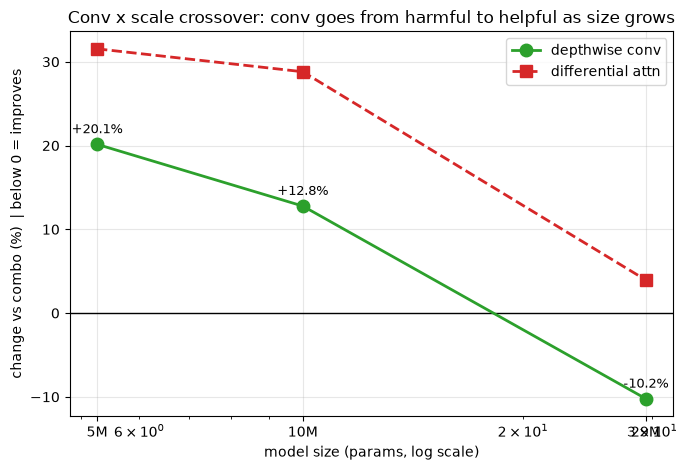

saved results/crossover.png + paper/fig_crossover.png


In [3]:
import numpy as np, csv
# load 3M & 10M from this run
def load_cross():
    d = {}
    with open("../results/crossover_runs.csv") as f:
        r = csv.reader(f); next(r, None)
        for sz, v, s, pm, pp in r: d.setdefault((sz, v), []).append(float(pp))
    return {k: float(np.mean(x)) for k, x in d.items()}, {k: float(np.mean([float(p) for p in []])) for k in []}
cross = {}
pmd = {}
with open("../results/crossover_runs.csv") as f:
    r = csv.reader(f); next(r, None)
    for sz, v, s, pm, pp in r:
        cross.setdefault((sz, v), []).append(float(pp)); pmd[sz] = float(pm)
cross = {k: float(np.mean(x)) for k, x in cross.items()}
# 30M from scale_confirm (2 seeds)
def load30(fn):
    d = {}
    with open(fn) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 3: d[row[0]] = float(row[2])
    return d
s0 = load30("../results/scale_confirm_runs.csv"); s1 = load30("../results/scale_confirm_s1_runs.csv")
m30 = {k: np.mean([s0[k], s1[k]]) for k in s0}

xs = [pmd["3M"], pmd["10M"], 29.4]
def deltas(variant, key30):
    return [100*(cross[("3M",variant)]-cross[("3M","combo")])/cross[("3M","combo")],
            100*(cross[("10M",variant)]-cross[("10M","combo")])/cross[("10M","combo")],
            100*(m30[key30]-m30["combo"])/m30["combo"]]
conv = deltas("combo_conv3", "combo_conv3")
diff = deltas("combo_diff", "combo_diff")
print("params:", [f"{x:.1f}M" for x in xs])
print("conv delta vs combo:", [f"{v:+.1f}%" for v in conv])
print("diff delta vs combo:", [f"{v:+.1f}%" for v in diff])

plt.figure(figsize=(7, 4.8))
plt.axhline(0, color="k", lw=1)
plt.plot(xs, conv, "o-", color="tab:green", lw=2, ms=9, label="depthwise conv")
plt.plot(xs, diff, "s--", color="tab:red", lw=2, ms=8, label="differential attn")
for x, y in zip(xs, conv): plt.annotate(f"{y:+.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.xscale("log"); plt.xticks(xs, [f"{x:.0f}M" for x in xs])
plt.xlabel("model size (params, log scale)"); plt.ylabel("change vs combo (%)  | below 0 = improves")
plt.title("Conv x scale crossover: conv goes from harmful to helpful as size grows")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../results/crossover.png", dpi=150)
import shutil; shutil.copy("../results/crossover.png", "../paper/fig_crossover.png")
plt.show(); print("saved results/crossover.png + paper/fig_crossover.png")


## Reading this

A monotone curve crossing zero is the clean version of the headline: the depthwise conv's value rises
with model scale, crossing from harmful (small) to helpful (~30M). Differential attention improves with
scale too but stays above zero (never a net win). This is the figure that makes the scale-dependence
claim concrete - though note (per the paper's positioning) that Primer already established conv gains
grow with scale at larger sizes; this is a controlled single-GPU characterization of the small-scale end.
